# EDA 04 — Analisis Korelasi Feature terhadap Volatilitas

Notebook ini digunakan untuk menganalisis hubungan antara feature numerik
(teknikal dan sentimen) dengan variabel target, yaitu volatilitas return saham.

Tujuan:
1. Mengidentifikasi feature yang paling berhubungan dengan volatilitas
2. Mengetahui potensi multikolinearitas antar feature
3. Mendukung tahap feature selection sebelum pemodelan XGBoost dan LSTM

Output digunakan pada:
BAB 4.4 Analisis Korelasi Feature terhadap Volatilitas

In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARY & KONFIGURASI PATH
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['figure.dpi'] = 200
plt.rcParams['figure.dpi'] = 200

ROOT_DIR = Path('../../')

PROCESSED_DIR = ROOT_DIR / '03_dataset' / 'processed'
OUTPUT_DIR = ROOT_DIR / '06_dokumen_tesis'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Processed:", PROCESSED_DIR.resolve())
print("Output   :", OUTPUT_DIR.resolve())

Processed: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed
Output   : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis


## Load Dataset Final

Dataset berisi feature teknikal, feature sentimen, dan target volatilitas.

In [2]:
# ════════════════════════════════════════════════════════════
# CELL 2 — LOAD DATASET GABUNGAN (output PREP_03)
# ════════════════════════════════════════════════════════════
# Memakai dataset_gabungan_X1X2Y.csv hasil PREP_03 — sudah berisi
# fitur teknikal (X1), skor sentimen (X2), dan volatilitas (Y).

FILE_GABUNG = ROOT_DIR / '03_dataset' / 'final' / 'dataset_gabungan_X1X2Y.csv'

assert FILE_GABUNG.exists(), (
    f'❌ File tidak ditemukan:\n{FILE_GABUNG.resolve()}\n'
    '→ Jalankan PREP_03 (integrasi) terlebih dahulu.'
)

df = pd.read_csv(FILE_GABUNG, encoding='utf-8-sig')
df.columns = df.columns.str.strip()
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.sort_values(['Emiten', 'Date']).reset_index(drop=True)

print("=" * 70)
print("DATASET GABUNGAN (X1 + X2 + Y)")
print("=" * 70)
print("Shape   :", df.shape)
print("Periode :", df['Date'].min().date(), "→", df['Date'].max().date())
print("Emiten  :", df['Emiten'].unique().tolist())
print("\nKolom   :")
for c in df.columns:
    print("  -", c)
print("\nMissing values:", int(df.isnull().sum().sum()))
display(df.head())

DATASET GABUNGAN (X1 + X2 + Y)
Shape   : (7315, 20)
Periode : 2022-01-31 → 2026-06-17
Emiten  : ['ADMR', 'ADRO', 'AKRA', 'ITMG', 'MEDC', 'PGAS', 'PTBA']

Kolom   :
  - Date
  - Emiten
  - Close
  - Log_Return
  - MA5
  - MA10
  - MA20
  - RSI14
  - Stoch_K
  - Stoch_D
  - Volume
  - Skor_Sentimen
  - N_Berita
  - Ada_Berita
  - Skor_Sentimen_Lag1
  - Skor_Sentimen_Lag2
  - Sentiment_MA3
  - Sentiment_MA20
  - Sentiment_STD20
  - Volatilitas

Missing values: 0


,Date,Emiten,Close,Log_Return,MA5,MA10,MA20,RSI14,Stoch_K,Stoch_D,Volume,Skor_Sentimen,N_Berita,Ada_Berita,Skor_Sentimen_Lag1,Skor_Sentimen_Lag2,Sentiment_MA3,Sentiment_MA20,Sentiment_STD20,Volatilitas
0,2022-01-31,ADMR,1270.0,0.094917,1034.263171,946.142090,714.430042,97.468207,85.852257,85.695761,112708200,0.1806,0,0,0.5000,0.5000,0.1806,0.18060,0.000000,0.037864
1,2022-02-02,ADMR,1185.0,-0.069274,1059.308105,986.492267,760.948692,87.253817,59.581262,77.593665,142984100,0.1806,0,0,0.1806,0.5000,0.1806,0.18060,0.000000,0.042552
2,2022-02-03,ADMR,1225.0,0.033198,1091.773743,1017.566528,806.446989,87.896624,65.119101,70.184207,164421400,0.1806,0,0,0.1806,0.1806,0.1806,0.18060,0.000000,0.042570
3,2022-02-04,ADMR,1235.0,0.008130,1126.094580,1044.002850,849.626315,88.058760,64.376821,63.025728,46328200,0.1806,0,0,0.1806,0.1806,0.1806,0.18060,0.000000,0.042438
4,2022-02-07,ADMR,1240.0,0.004041,1141.863623,1067.656409,889.512701,88.144279,65.113022,64.869648,45876900,0.9138,1,1,0.1806,0.1806,0.4250,0.32724,0.327897,0.042360


## Heatmap Korelasi Semua Feature Numerik

Korelasi Pearson digunakan untuk melihat hubungan linear antar feature.
Output digunakan sebagai Gambar 4.9

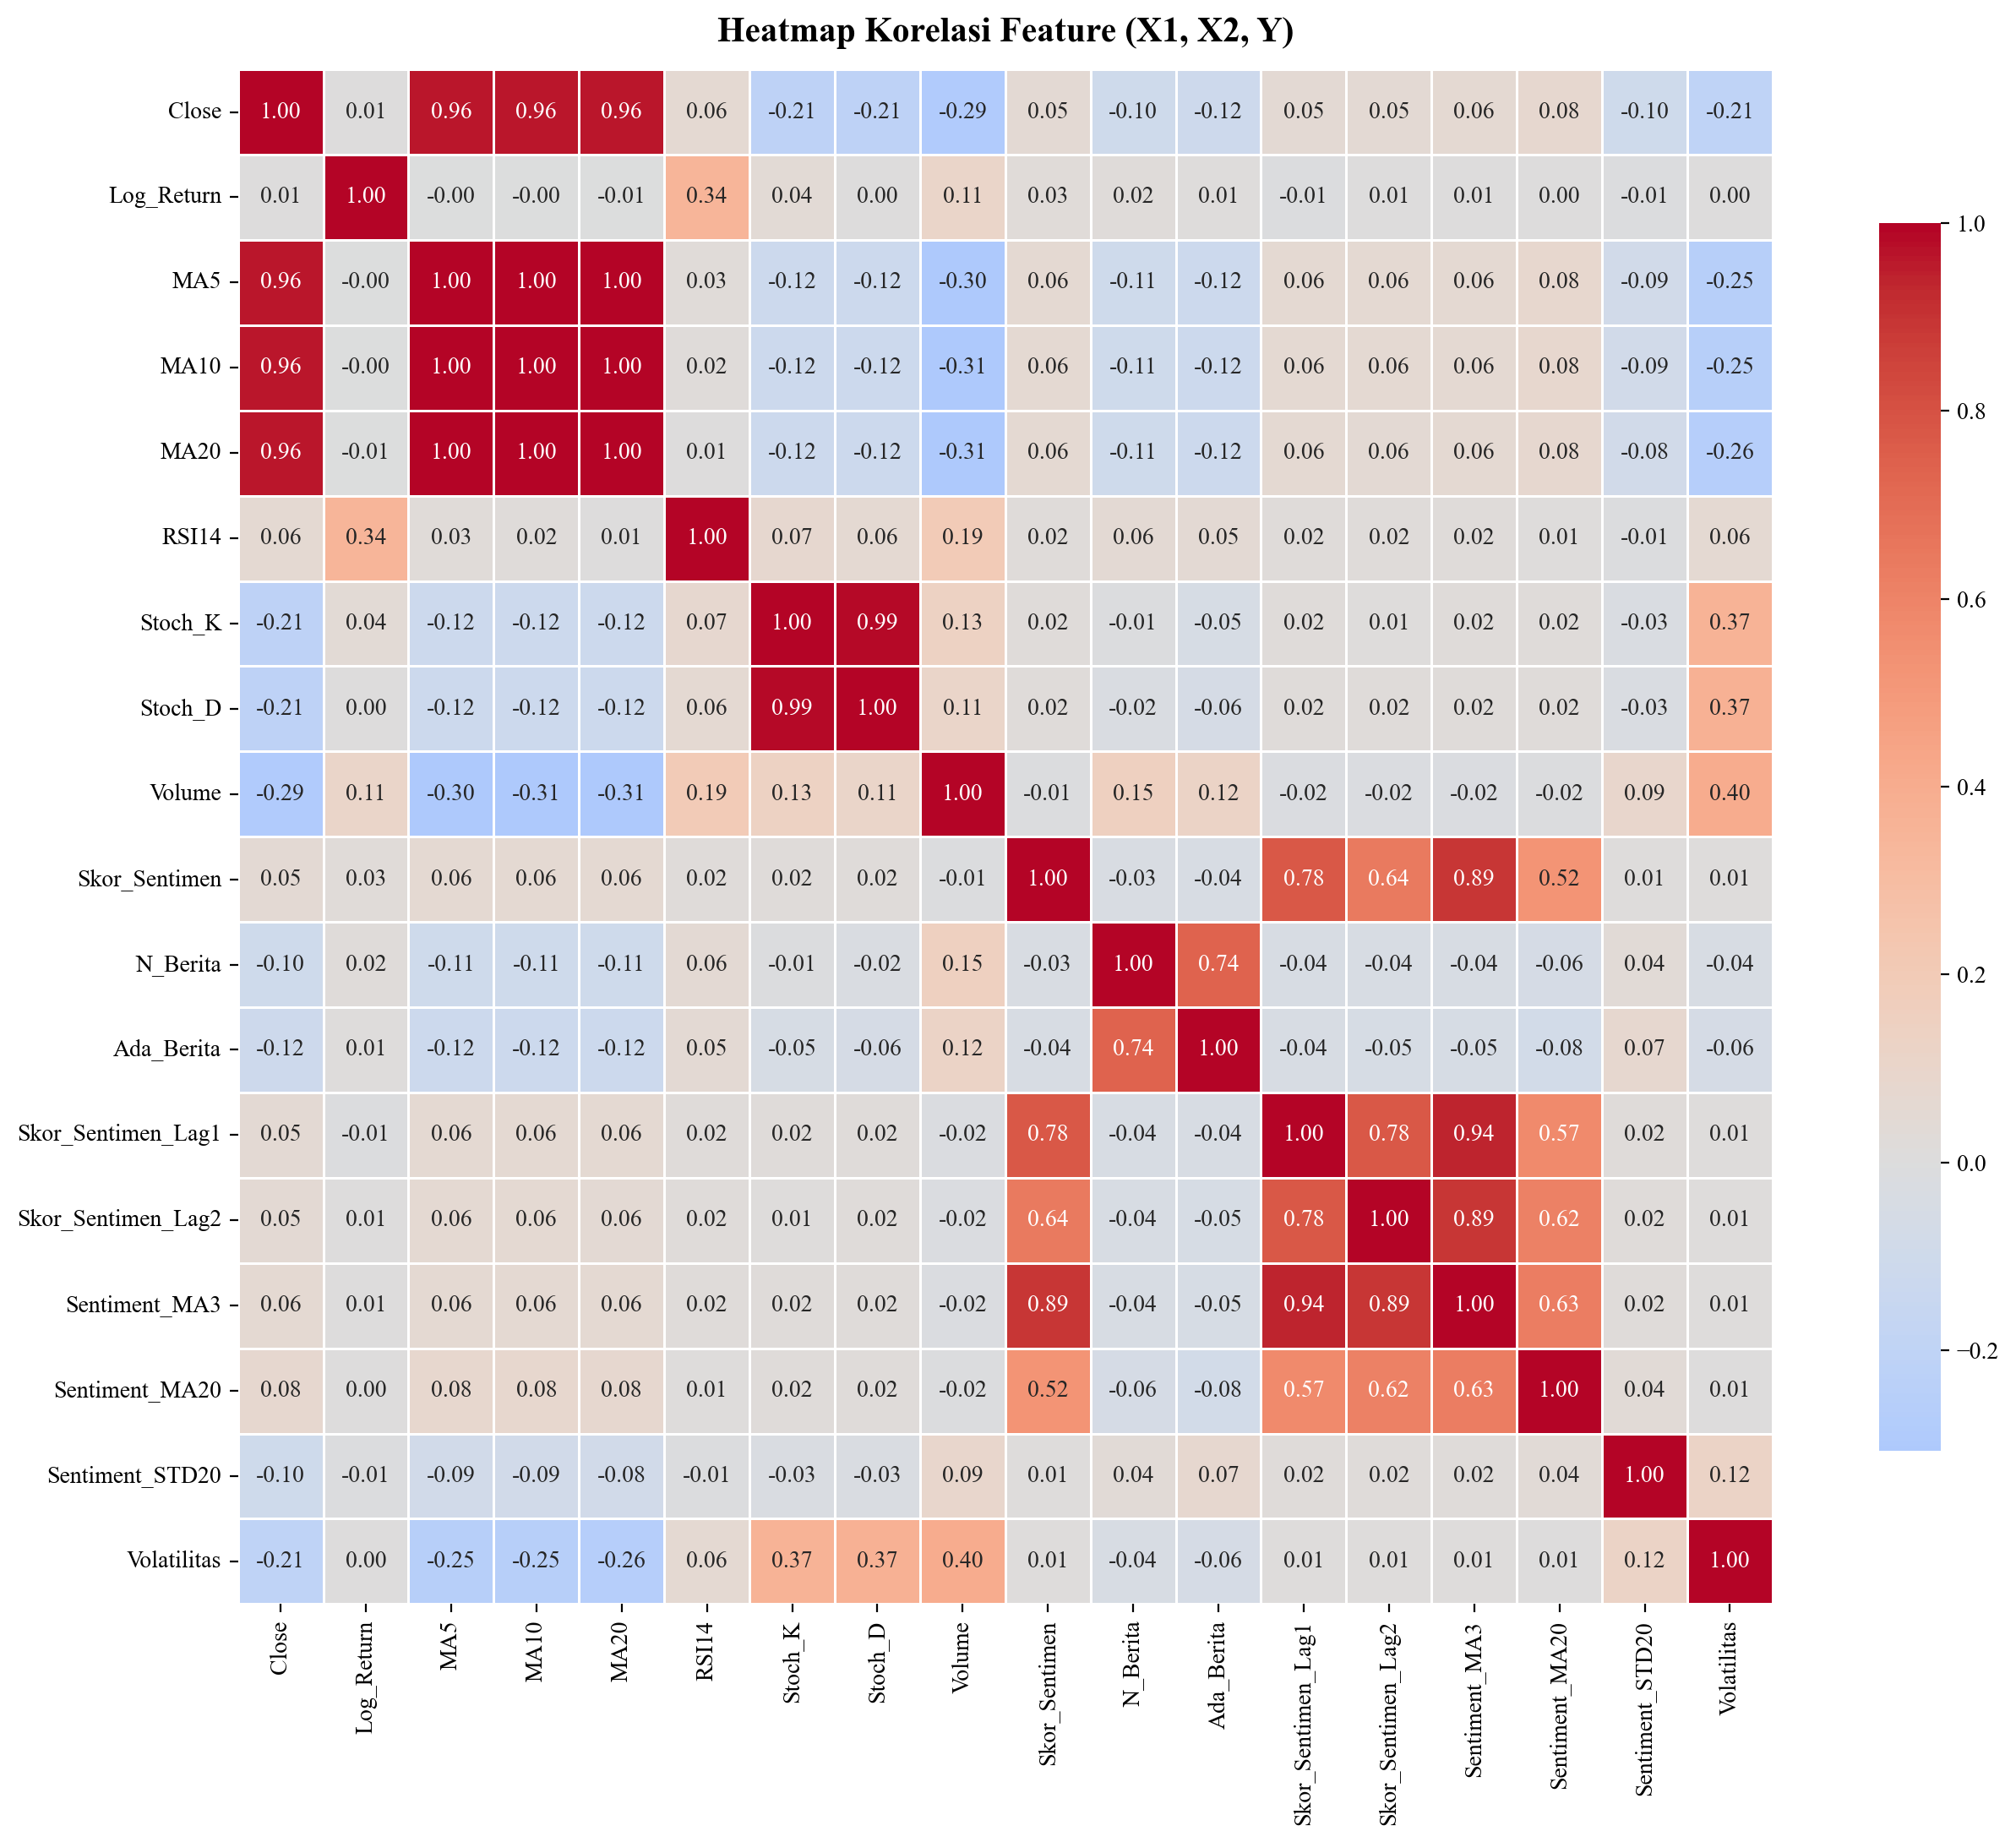

Korelasi tiap fitur terhadap VOLATILITAS (urut tertinggi → terendah):
Volume                0.398
Stoch_D               0.372
Stoch_K               0.366
Sentiment_STD20       0.118
RSI14                 0.065
Skor_Sentimen_Lag2    0.014
Sentiment_MA3         0.014
Skor_Sentimen_Lag1    0.013
Skor_Sentimen         0.011
Sentiment_MA20        0.010
Log_Return            0.003
N_Berita             -0.045
Ada_Berita           -0.059
Close                -0.209
MA5                  -0.255
MA10                 -0.255
MA20                 -0.256

── Fokus fitur SENTIMEN (X2) ──
  Skor_Sentimen       : +0.011
  Skor_Sentimen_Lag1  : +0.013
  Sentiment_MA20      : +0.010
  Sentiment_STD20     : +0.118


In [3]:
# ════════════════════════════════════════════════════════════
# CELL 3 — HEATMAP KORELASI FEATURE
# ════════════════════════════════════════════════════════════

# Ambil hanya kolom numerik (buang Date & Emiten yang non-numerik)
numeric_df = df.drop(columns=['Date', 'Emiten'], errors='ignore').select_dtypes('number')

# Matriks korelasi Pearson
corr_matrix = numeric_df.corr(method='pearson')

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8},
)
plt.title("Heatmap Korelasi Feature (X1, X2, Y)", fontsize=15, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Gambar_4_9_heatmap_korelasi_feature.png',
            dpi=200, bbox_inches='tight')
plt.show()

# ── Ringkasan: korelasi tiap fitur terhadap target Volatilitas (untuk RQ1)
if 'Volatilitas' in corr_matrix.columns:
    korr_vol = (corr_matrix['Volatilitas']
                .drop('Volatilitas')
                .sort_values(ascending=False))
    print("Korelasi tiap fitur terhadap VOLATILITAS (urut tertinggi → terendah):")
    print(korr_vol.round(3).to_string())

    # Sorot korelasi fitur sentimen secara khusus
    print("\n── Fokus fitur SENTIMEN (X2) ──")
    for c in ['Skor_Sentimen','Skor_Sentimen_Lag1','Sentiment_MA20','Sentiment_STD20']:
        if c in korr_vol.index:
            print(f"  {c:20}: {korr_vol[c]:+.3f}")

"Korelasi linear sentimen terhadap volatilitas tergolong lemah (0,06), namun hal ini tidak serta-merta menafikan pengaruh sentimen, mengingat hubungan di pasar finansial umumnya bersifat nonlinear dan bergantung pada lag serta intensitas sentimen. Oleh karena itu, pengaruh sentimen dianalisis lebih lanjut melalui (1) analisis lead-lag dan (2) kontribusi fitur (feature importance) pada model XGBoost/LSTM."

## Korelasi Feature terhadap Volatilitas

Mengurutkan feature berdasarkan kekuatan hubungan dengan variabel target.
Output digunakan sebagai Tabel 4.8

In [4]:
# ============================================================
# CELL 4 — KORELASI FEATURE VS TARGET
# ============================================================

target = 'Volatilitas'

corr_target = (
    numeric_df
    .corr()[target]
    .drop(target)
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
)

corr_table = pd.DataFrame({
    'Feature': corr_target.index,
    'Correlation_with_Volatilitas': corr_target.values
})

display(corr_table)

corr_table.to_csv(
    OUTPUT_DIR / 'Tabel_4_8_korelasi_feature_target.csv',
    index=False,
    encoding='utf-8-sig'
)

,Feature,Correlation_with_Volatilitas
0,Volume,0.398413
1,Stoch_D,0.372034
2,Stoch_K,0.366171
3,MA20,-0.255565
4,MA10,-0.254677
5,MA5,-0.254632
6,Close,-0.208807
7,Sentiment_STD20,0.118074
8,RSI14,0.064758
9,Ada_Berita,-0.059393


## Barplot Korelasi Feature terhadap Volatilitas

Visualisasi ranking feature yang paling berhubungan dengan volatilitas.
Output digunakan sebagai Gambar 4.10

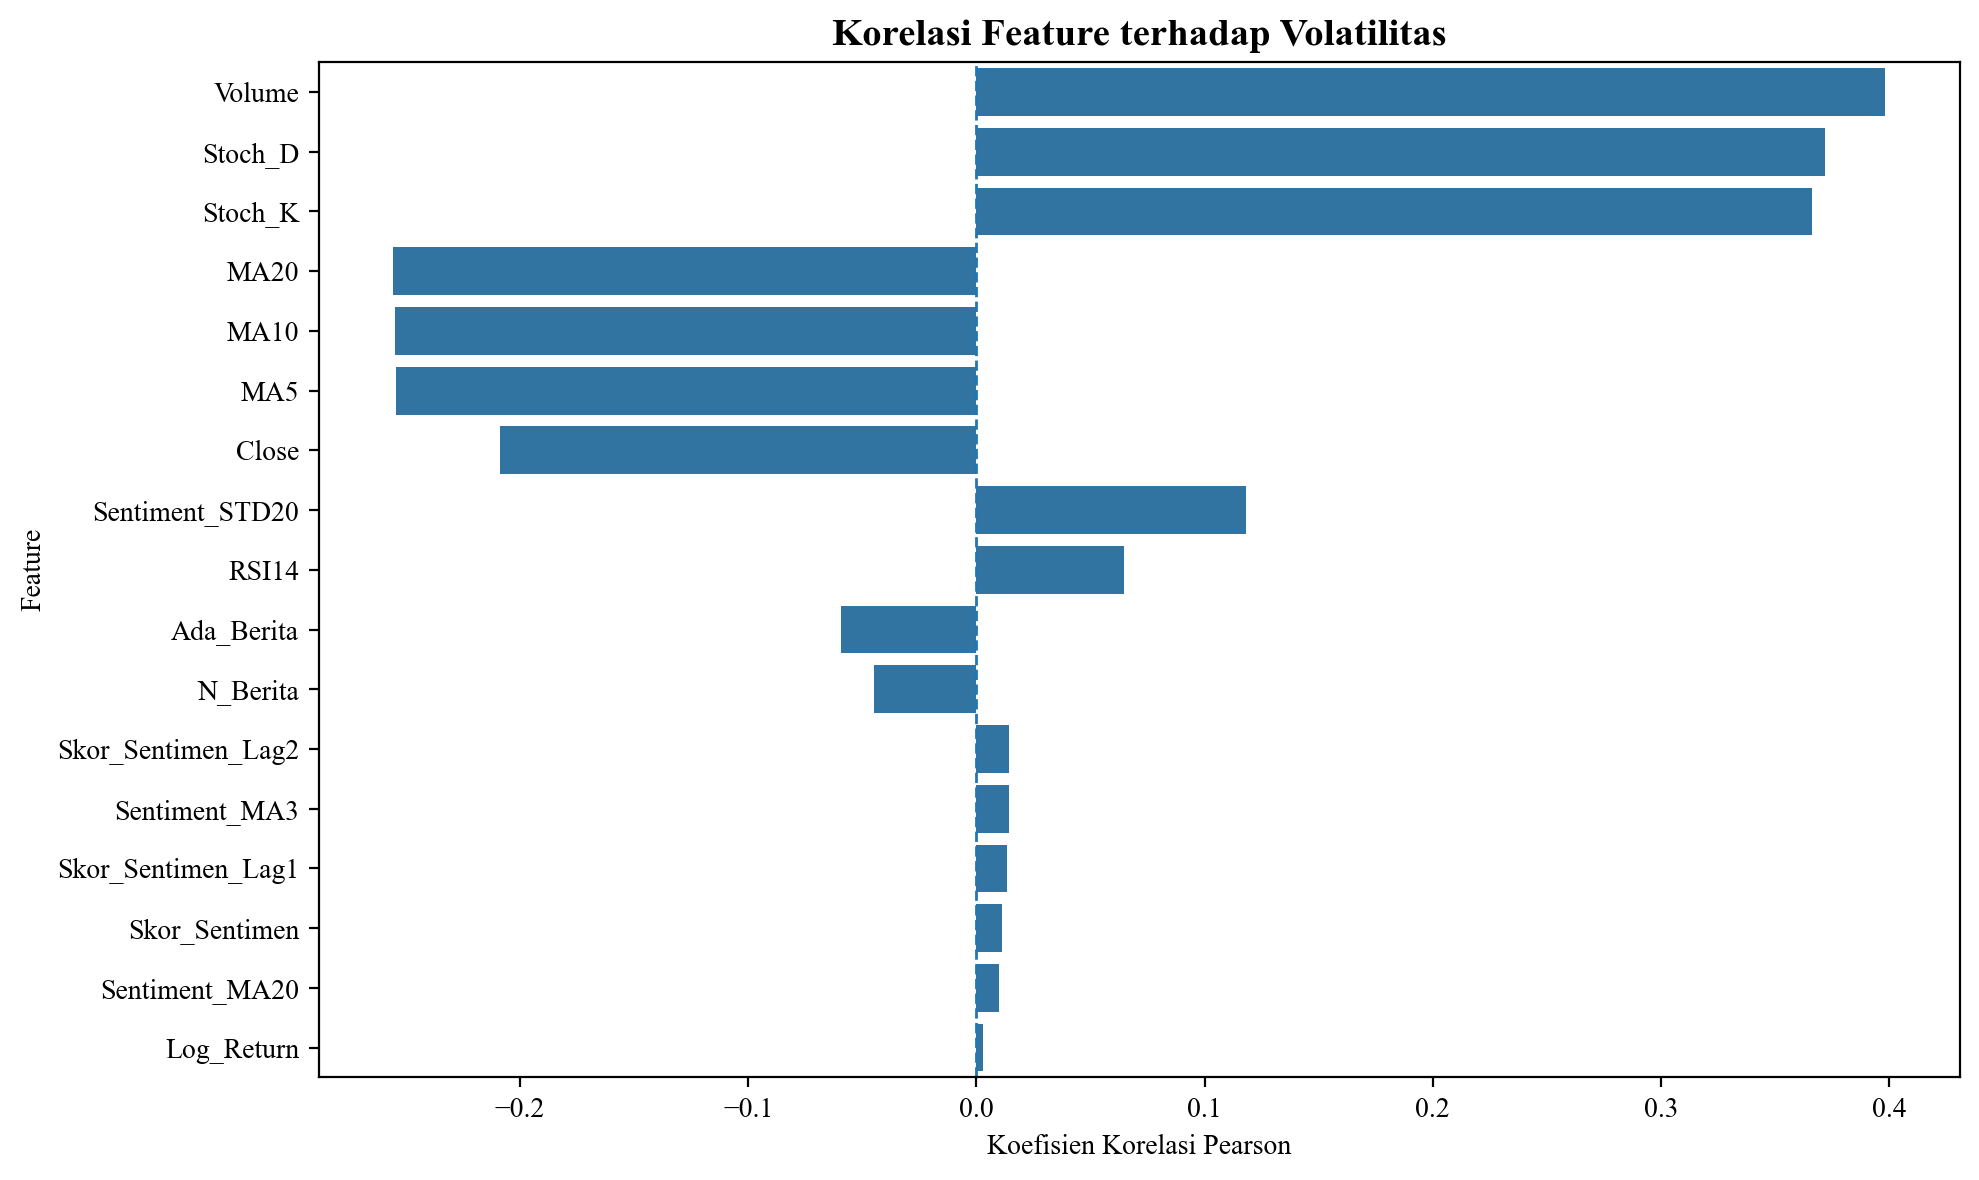

In [5]:
# ============================================================
# CELL 5 — BARPLOT KORELASI FEATURE
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=corr_table,
    x='Correlation_with_Volatilitas',
    y='Feature'
)

plt.axvline(0, linestyle='--', linewidth=1)

plt.title(
    "Korelasi Feature terhadap Volatilitas",
    fontsize=14,
    fontweight='bold'
)

plt.xlabel("Koefisien Korelasi Pearson")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'Gambar_4_10_barplot_korelasi_feature.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## Deteksi Multikolinearitas

Feature dengan korelasi absolut > 0.80 dianggap memiliki multikolinearitas tinggi.

In [6]:
# ============================================================
# CELL 6 — MULTIKOLINEARITAS
# ============================================================

high_corr_pairs = []

corr_abs = corr_matrix.abs()

for i in range(len(corr_abs.columns)):
    for j in range(i):
        if corr_abs.iloc[i, j] > 0.80:
            high_corr_pairs.append({
                'Feature_1': corr_abs.columns[i],
                'Feature_2': corr_abs.columns[j],
                'Correlation': corr_abs.iloc[i, j]
            })

multi_df = pd.DataFrame(high_corr_pairs)

display(multi_df)

,Feature_1,Feature_2,Correlation
0,MA5,Close,0.963602
1,MA10,Close,0.962503
2,MA10,MA5,0.999788
3,MA20,Close,0.960289
4,MA20,MA5,0.998998
5,MA20,MA10,0.999555
6,Stoch_D,Stoch_K,0.987185
7,Sentiment_MA3,Skor_Sentimen,0.889071
8,Sentiment_MA3,Skor_Sentimen_Lag1,0.938778
9,Sentiment_MA3,Skor_Sentimen_Lag2,0.888089


## Ringkasan Output
Semua output telah disimpan ke folder dokumen tesis.

In [7]:
# ============================================================
# CELL 7 — SUMMARY OUTPUT
# ============================================================

files = [
    'Gambar_4_9_heatmap_korelasi_feature.png',
    'Tabel_4_8_korelasi_feature_target.csv',
    'Gambar_4_10_barplot_korelasi_feature.png'
]

print("Output berhasil disimpan:")
for file in files:
    print("-", OUTPUT_DIR / file)

print()
print("Interpretasi:")
print("- Korelasi positif: feature naik → volatilitas cenderung naik")
print("- Korelasi negatif: feature naik → volatilitas cenderung turun")
print("- Korelasi tinggi dapat digunakan untuk feature selection")

Output berhasil disimpan:
- ..\..\06_dokumen_tesis\Gambar_4_9_heatmap_korelasi_feature.png
- ..\..\06_dokumen_tesis\Tabel_4_8_korelasi_feature_target.csv
- ..\..\06_dokumen_tesis\Gambar_4_10_barplot_korelasi_feature.png

Interpretasi:
- Korelasi positif: feature naik → volatilitas cenderung naik
- Korelasi negatif: feature naik → volatilitas cenderung turun
- Korelasi tinggi dapat digunakan untuk feature selection


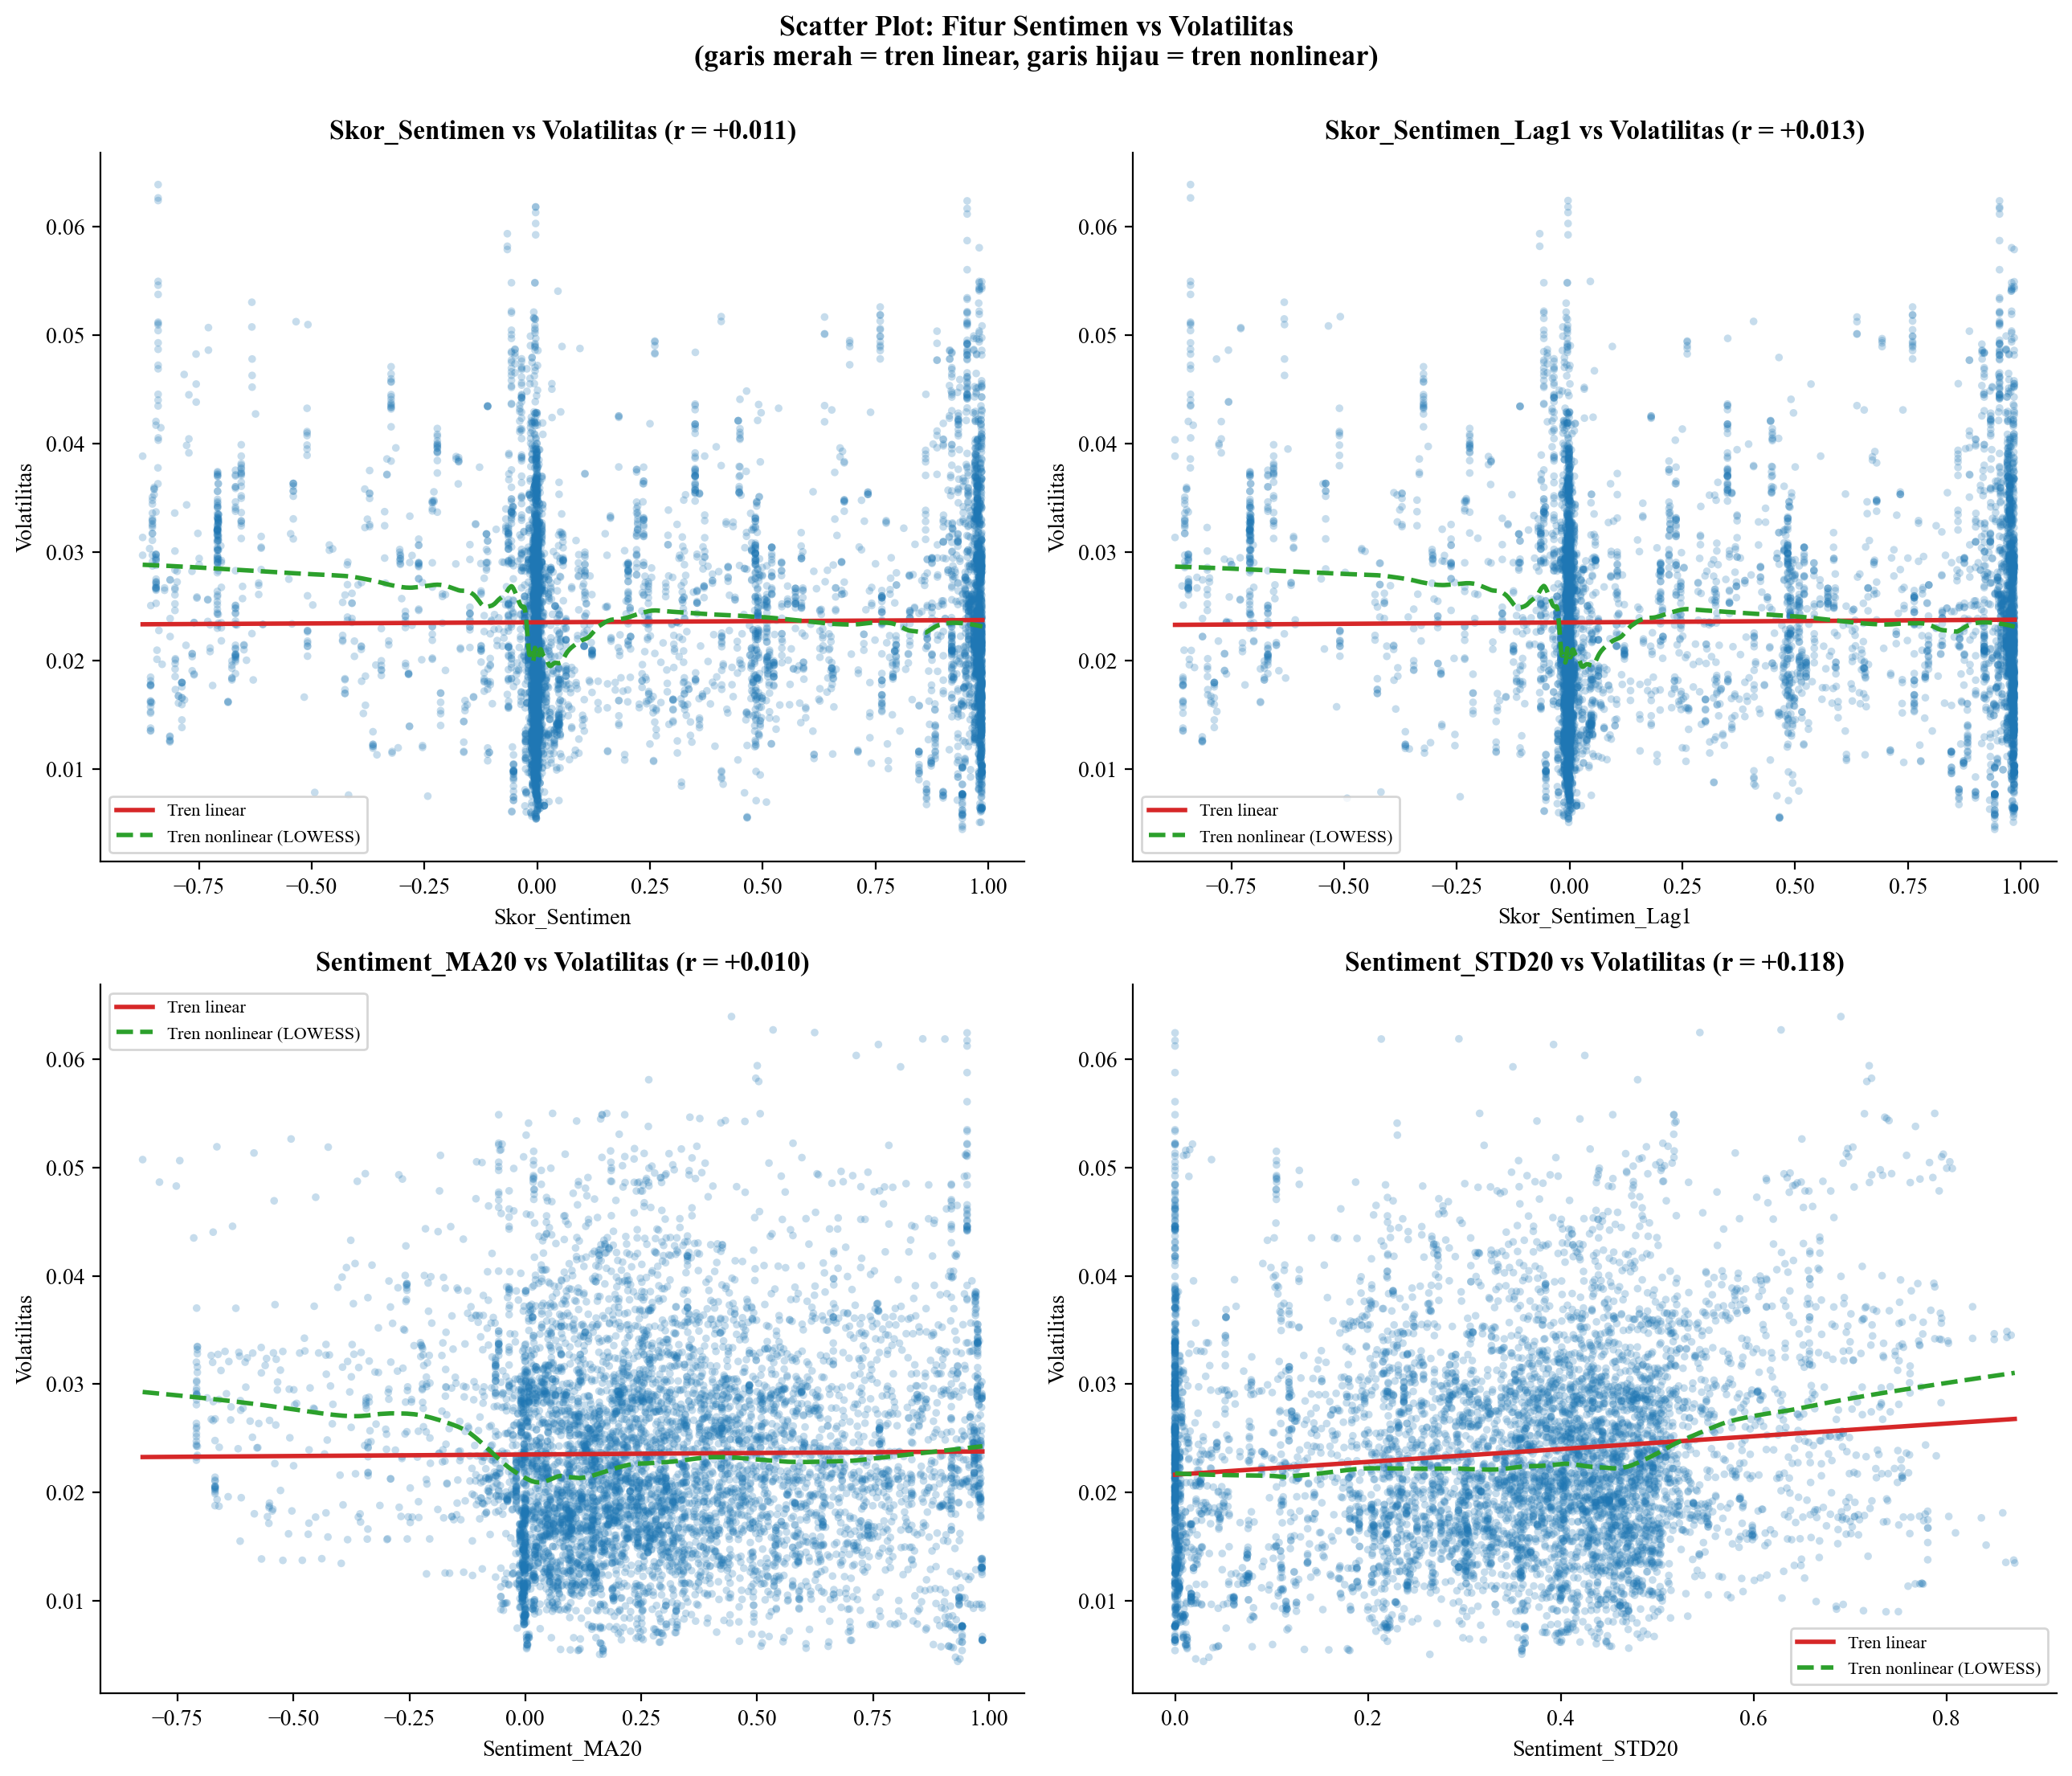

In [8]:
# ════ SEL — SCATTER PLOT SENTIMEN vs VOLATILITAS (cek bentuk hubungan) ════
fitur_sentimen = ['Skor_Sentimen','Skor_Sentimen_Lag1','Sentiment_MA20','Sentiment_STD20']
fitur_sentimen = [f for f in fitur_sentimen if f in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for i, fitur in enumerate(fitur_sentimen):
    ax = axes[i]
    x = df[fitur]; y = df['Volatilitas']
    # scatter
    ax.scatter(x, y, alpha=0.25, s=12, color='#1f77b4', edgecolors='none')
    # garis tren (regresi linear sederhana)
    m, b = np.polyfit(x.dropna(), y[x.notna()], 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, m*xs+b, color='#d62728', lw=2, label=f'Tren linear')
    # garis LOWESS (tren nonlinear) — kalau ada statsmodels
    try:
        import statsmodels.api as sm
        lo = sm.nonparametric.lowess(y, x, frac=0.3)
        ax.plot(lo[:,0], lo[:,1], color='#2ca02c', lw=2, ls='--', label='Tren nonlinear (LOWESS)')
    except Exception:
        pass
    r = x.corr(y)
    ax.set_title(f'{fitur} vs Volatilitas (r = {r:+.3f})', fontweight='bold')
    ax.set_xlabel(fitur); ax.set_ylabel('Volatilitas')
    ax.legend(fontsize=8); ax.spines[['top','right']].set_visible(False)

fig.suptitle('Scatter Plot: Fitur Sentimen vs Volatilitas\n(garis merah = tren linear, garis hijau = tren nonlinear)',
             fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gambar_scatter_sentimen_volatilitas.png', dpi=200, bbox_inches='tight')
plt.show()